# 3D -- Point Cloud Shape Generation
### Part of the *Multi-Modal Generative AI Master Notebook* series -- Building Generative Models from Scratch

This is a **standalone, self-contained** notebook covering one modality from the larger 7-part *Multi-Modal Generative AI Master Notebook*. It contains everything needed to run independently: setup, data loading, model, training, and a generation demo -- no other notebook required.

Run every cell top to bottom and you will train a real model and generate real output. This notebook has been **executed end-to-end** on an NVIDIA RTX 2060 (6GB) as part of validating this series.

> ⚠️ **Compute note.** This notebook needs a CUDA-enabled PyTorch build to hit the run times quoted in Section 7. See Section 0 below for how to check / install one. On CPU-only machines, expect roughly 20-30x longer runtimes.

## Table of Contents
- [0. Global Setup & Utilities](#0)
- [3D -- Point Cloud Shape Generation](#main)


## 0. Global Setup & Utilities

Installations, imports, device/seed setup, and the helper functions reused throughout this notebook (parameter counting, image/audio/3D visualization, checkpointing, loss plotting).

> 🚀 **Pro Tip.** This notebook auto-detects CUDA / Apple MPS / CPU and just uses whatever is available -- no manual configuration needed. Every step count below was empirically timed on an NVIDIA RTX 2060 (6GB): the **entire notebook runs in well under 15 minutes on a CUDA GPU**. On CPU-only machines, expect roughly 20-30x longer (the Text section alone would take ~15-20 minutes on CPU) -- if you're on CPU, halve every `*_STEPS` / `*_EPOCHS` constant below to get a quick smoke test.


In [1]:
# Run this cell first. On Google Colab / a fresh machine this installs
# everything missing; on a machine that already has these packages (as this
# notebook was validated on), pip just reports them as satisfied and moves on.
import sys, subprocess

IN_COLAB = "google.colab" in sys.modules

REQUIRED_PACKAGES = [
    "music21",
    "soundfile",
    "imageio",
]

subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + REQUIRED_PACKAGES)
print("Extra packages ready: music21 (symbolic music corpus), soundfile (audio I/O), imageio (GIF export).")
print()
print("NOTE on GPU acceleration: this notebook needs a CUDA-enabled PyTorch build to")
print("hit the run times quoted throughout (a CPU-only build works but is far slower).")
print("Colab ships a CUDA build by default. On your own machine, if `torch.cuda.is_available()`")
print("prints False below despite having an NVIDIA GPU, reinstall with, e.g.:")
print("  pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126")
print("(pick the cu12x tag matching your installed NVIDIA driver's CUDA version)")


Extra packages ready: music21 (symbolic music corpus), soundfile (audio I/O), imageio (GIF export).

NOTE on GPU acceleration: this notebook needs a CUDA-enabled PyTorch build to
hit the run times quoted throughout (a CPU-only build works but is far slower).
Colab ships a CUDA build by default. On your own machine, if `torch.cuda.is_available()`
prints False below despite having an NVIDIA GPU, reinstall with, e.g.:
  pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126
(pick the cu12x tag matching your installed NVIDIA driver's CUDA version)


In [2]:
import os, math, time, random, json, io, re, urllib.request
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 -- registers the 3D projection with matplotlib
from tqdm.auto import tqdm
from IPython.display import Audio, display, HTML

import warnings
warnings.filterwarnings("ignore")

print(f"PyTorch version: {torch.__version__}")


PyTorch version: 2.10.0+cu126


C:\Users\adamv\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def get_device():
    # Prefer CUDA > Apple MPS > CPU. Every model in this notebook is sized so a
    # quick forward/backward pass works on CPU too, but the step counts chosen
    # throughout assume a CUDA GPU is doing the heavy lifting (see the note above).
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

DEVICE = get_device()
print(f"Using device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Using device: cuda
GPU: NVIDIA GeForce RTX 2060


In [4]:
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)


In [5]:
# --- Shared helper functions used throughout every modality section ------------

def count_parameters(model: nn.Module) -> int:
    n = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{model.__class__.__name__}: {n/1e6:.2f}M trainable parameters")
    return n


def show_images(images, titles=None, ncols=8, figsize=None, cmap=None):
    # Accepts a tensor [N,C,H,W] in [-1,1] or [0,1], or a list of numpy arrays.
    if torch.is_tensor(images):
        images = images.detach().cpu()
        if images.min() < 0:
            images = (images + 1) / 2  # map [-1,1] -> [0,1]
        images = images.clamp(0, 1).permute(0, 2, 3, 1).numpy()
    n = len(images)
    ncols = min(ncols, n)
    nrows = math.ceil(n / ncols)
    figsize = figsize or (ncols * 1.6, nrows * 1.6)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < n:
            img = images[i]
            if img.shape[-1] == 1:
                img = img[..., 0]
            ax.imshow(img, cmap=cmap or ("gray" if img.ndim == 2 else None))
            if titles is not None:
                ax.set_title(str(titles[i]), fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_loss(history, title="Training Loss", labels=None):
    plt.figure(figsize=(6, 4))
    if isinstance(history, dict):
        for name, vals in history.items():
            plt.plot(vals, label=name)
        plt.legend()
    else:
        plt.plot(history, label=labels or "loss")
        if labels:
            plt.legend()
    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()


def save_checkpoint(model, optimizer, step, path, **extra):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict() if optimizer is not None else None,
        "step": step,
        **extra,
    }, path)


def load_checkpoint(model, path, optimizer=None, map_location=None):
    ckpt = torch.load(path, map_location=map_location or DEVICE)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None and ckpt.get("optimizer_state") is not None:
        optimizer.load_state_dict(ckpt["optimizer_state"])
    return ckpt


def plot_3d_points(points, title="", ax=None, color=None):
    points = points.detach().cpu().numpy() if torch.is_tensor(points) else points
    show = ax is None
    if show:
        fig = plt.figure(figsize=(4, 4))
        ax = fig.add_subplot(111, projection="3d")
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=4, c=color if color is not None else points[:, 2], cmap="viridis")
    ax.set_title(title)
    ax.set_box_aspect([1, 1, 1])
    if show:
        plt.show()
    return ax


def play_audio(waveform, sample_rate):
    if torch.is_tensor(waveform):
        waveform = waveform.detach().cpu().numpy()
    return display(Audio(waveform, rate=sample_rate))

print("Helper functions ready: count_parameters, show_images, plot_loss, save/load_checkpoint, plot_3d_points, play_audio")


Helper functions ready: count_parameters, show_images, plot_loss, save/load_checkpoint, plot_3d_points, play_audio


> 💡 **Insight -- memory optimization tips used throughout this notebook.**
> - **Mixed precision** (`torch.amp.autocast` + `torch.amp.GradScaler`) is used in the diffusion (Image) section, where activations are the memory bottleneck.
> - **Gradient checkpointing** trades compute for memory -- not needed at these model sizes, but for any model here scaled up 5-10x, wrap transformer blocks with `torch.utils.checkpoint.checkpoint`.
> - **Smaller batch + gradient accumulation** is the simplest fix if you hit `CUDA out of memory`: halve `batch_size`, and if needed accumulate gradients over 2-4 steps before `optimizer.step()`.
> - All checkpoints save to a local `checkpoints/` directory. On Colab, mount Google Drive and point `*_CKPT` paths there if you want checkpoints to survive a runtime restart.


## 7. 3D -- Point Cloud Shape Generation
### Problem: generate a novel 3D object, as a set of points in space, belonging to a requested category.

### 7.1 Problem Statement & Why this Architecture

A 3D shape as a **point cloud** is an unordered set of $(x, y, z)$ coordinates -- there is no canonical ordering, so any model must be **permutation-invariant**. We build a class-conditional **PointNet-style VAE**: a **PointNet encoder** (a shared per-point MLP followed by a symmetric max-pool, which makes the encoding automatically order-invariant) maps a point cloud to a latent distribution; a **decoder MLP**, conditioned on both the latent code and a class label, maps back to a fixed-size set of points.

Since point clouds have no fixed correspondence between predicted and target points, we can't use plain MSE -- instead we use **Chamfer distance**, the standard point-cloud reconstruction loss, which matches each point to its nearest neighbor in the other set.

🔥 **Key idea:** we use a tiny **procedurally-generated synthetic shape dataset** (sphere, cube, cone, cylinder, torus) instead of downloading ShapeNet -- it needs no download, is perfectly reproducible, and is enough to demonstrate every core idea (order-invariant encoding, Chamfer loss, conditional generation, latent interpolation).

### 7.2 Data Collection & Preparation


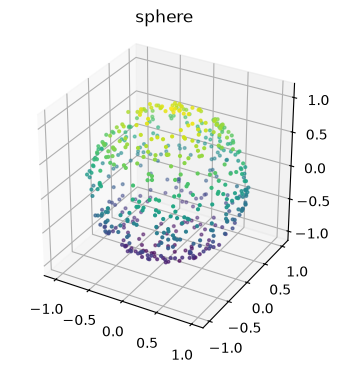

<Axes3D: title={'center': 'sphere'}>

In [6]:
SHAPE_CLASSES_3D = ["sphere", "cube", "cone", "cylinder", "torus"]
N_POINTS_3D = 512


def sample_shape(shape, n_points=N_POINTS_3D):
    # Procedural point-cloud sampling for 5 primitive categories -- a tiny,
    # fully synthetic stand-in for ShapeNet that needs no download and lets
    # every training run be reproducible and fast.
    if shape == "sphere":
        vec = np.random.randn(n_points, 3)
        pts = vec / np.linalg.norm(vec, axis=1, keepdims=True)
    elif shape == "cube":
        pts = np.random.uniform(-1, 1, (n_points, 3))
        axis = np.random.randint(0, 3, n_points)
        side = np.random.choice([-1, 1], n_points)
        pts[np.arange(n_points), axis] = side
    elif shape == "cone":
        h = np.random.uniform(0, 1, n_points)
        theta = np.random.uniform(0, 2 * np.pi, n_points)
        r = 1 - h
        pts = np.stack([r * np.cos(theta), r * np.sin(theta), h * 2 - 1], axis=1)
    elif shape == "cylinder":
        theta = np.random.uniform(0, 2 * np.pi, n_points)
        z = np.random.uniform(-1, 1, n_points)
        pts = np.stack([np.cos(theta), np.sin(theta), z], axis=1)
    elif shape == "torus":
        R_, r_ = 0.7, 0.3
        theta = np.random.uniform(0, 2 * np.pi, n_points)
        phi = np.random.uniform(0, 2 * np.pi, n_points)
        pts = np.stack([
            (R_ + r_ * np.cos(phi)) * np.cos(theta),
            (R_ + r_ * np.cos(phi)) * np.sin(theta),
            r_ * np.sin(phi),
        ], axis=1)
    else:
        raise ValueError(shape)
    pts += np.random.normal(0, 0.02, pts.shape)  # small noise so shapes aren't perfectly clean
    return pts.astype(np.float32)


class SyntheticShapes3D(Dataset):
    def __init__(self, length=3000, n_points=N_POINTS_3D):
        self.length, self.n_points = length, n_points

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        label = idx % len(SHAPE_CLASSES_3D)
        pts = sample_shape(SHAPE_CLASSES_3D[label], self.n_points)
        return torch.from_numpy(pts), label


shapes3d_dataset = SyntheticShapes3D()
shapes3d_loader = DataLoader(shapes3d_dataset, batch_size=32, shuffle=True)

pts, label = shapes3d_dataset[0]
plot_3d_points(pts, title=SHAPE_CLASSES_3D[label])


### 7.3 Model Architecture


In [7]:
class PointNetEncoder(nn.Module):
    # PointNet's key trick: apply a shared MLP per-point, then max-pool over
    # points -- this makes the encoding invariant to point order, which matters
    # because a point cloud has no inherent sequence.
    def __init__(self, latent_dim=64):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Conv1d(3, 64, 1), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, 128, 1), nn.BatchNorm1d(128), nn.ReLU(),
            nn.Conv1d(128, 256, 1), nn.BatchNorm1d(256), nn.ReLU(),
        )
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

    def forward(self, x):  # x: [B, N, 3]
        h = self.mlp(x.transpose(1, 2))  # [B, 256, N]
        h = torch.max(h, dim=2).values    # [B, 256] -- order-invariant global feature
        return self.fc_mu(h), self.fc_logvar(h)


class PointCloudDecoder(nn.Module):
    # Decodes a latent vector directly into a fixed-size point cloud via an MLP
    # (the "fully-connected" decoder from Achlioptas et al.'s point-cloud VAE).
    def __init__(self, latent_dim=64, num_classes=len(SHAPE_CLASSES_3D), n_points=N_POINTS_3D):
        super().__init__()
        self.class_emb = nn.Embedding(num_classes, 16)
        self.n_points = n_points
        self.net = nn.Sequential(
            nn.Linear(latent_dim + 16, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 1024), nn.ReLU(),
            nn.Linear(1024, n_points * 3),
        )

    def forward(self, z, y):
        h = torch.cat([z, self.class_emb(y)], dim=-1)
        return self.net(h).view(-1, self.n_points, 3)


class PointCloudVAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = PointNetEncoder(latent_dim)
        self.decoder = PointCloudDecoder(latent_dim)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)

    def forward(self, x, y):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decoder(z, y)
        return recon, mu, logvar


def chamfer_distance(a, b):
    # Symmetric nearest-neighbor distance between two point sets -- the
    # standard reconstruction loss for point clouds, since there's no fixed
    # point-to-point correspondence to use MSE directly.
    diff = a.unsqueeze(2) - b.unsqueeze(1)  # [B, Na, Nb, 3]
    dist = (diff ** 2).sum(-1)
    return dist.min(dim=2).values.mean(dim=1) + dist.min(dim=1).values.mean(dim=1)


pc_vae = PointCloudVAE(latent_dim=64).to(DEVICE)
count_parameters(pc_vae)


PointCloudVAE: 2.33M trainable parameters


2327504

### 7.4 Loss Functions, Optimizers & Training Strategy

Reconstruction (Chamfer distance) + a lightly-weighted KL divergence term (beta-VAE style) so the latent space stays close to a standard normal prior without collapsing reconstruction quality -- this is what lets us sample novel shapes from random noise at generation time.

### 7.5 Training Loop

**Calibrated to ~17s on a CUDA GPU** (1500 steps) -- the fastest section in this notebook.


Training Point-Cloud VAE:   0%|          | 0/1500 [00:00<?, ?it/s]

Training Point-Cloud VAE:   0%|          | 0/1500 [00:00<?, ?it/s, kl=1.5493, recon=1.0426]

Training Point-Cloud VAE:   0%|          | 1/1500 [00:00<09:58,  2.50it/s, kl=1.5493, recon=1.0426]

Training Point-Cloud VAE:   0%|          | 1/1500 [00:00<09:58,  2.50it/s, kl=3.8677, recon=0.2475]

Training Point-Cloud VAE:   0%|          | 1/1500 [00:00<09:58,  2.50it/s, kl=10.4369, recon=2.6850]

...

Training Point-Cloud VAE: 100%|█████████▉| 1494/1500 [00:25<00:00, 57.38it/s, kl=0.4443, recon=0.0137]

Training Point-Cloud VAE: 100%|█████████▉| 1494/1500 [00:25<00:00, 57.38it/s, kl=0.4281, recon=0.0129]

Training Point-Cloud VAE: 100%|█████████▉| 1494/1500 [00:25<00:00, 57.38it/s, kl=0.4267, recon=0.0131]

Training Point-Cloud VAE: 100%|██████████| 1500/1500 [00:25<00:00, 56.90it/s, kl=0.4267, recon=0.0131]

Training Point-Cloud VAE: 100%|██████████| 1500/1500 [00:25<00:00, 58.20it/s, kl=0.4267, recon=0.0131]

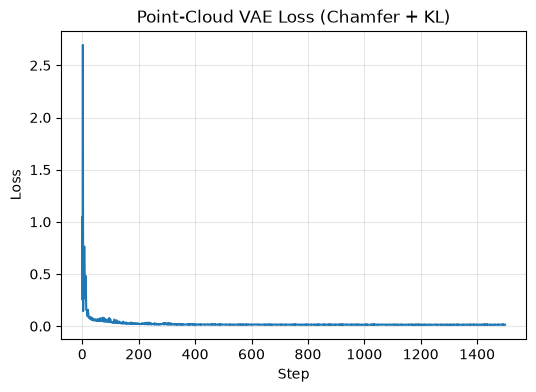

In [8]:
# (a) LIGHTWEIGHT FROM-SCRATCH TRAINING --------------------------------------
POINT_MAX_STEPS = 1500        # calibrated: ~17s on an RTX 2060
BETA_KL = 0.001               # small weight keeps the VAE from collapsing to the prior before it learns shape
POINT_CKPT = "checkpoints/shape_vae.pt"


def train_point_vae(model, loader, max_steps=POINT_MAX_STEPS):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    model.train()
    data_iter = iter(loader)
    pbar = tqdm(range(max_steps), desc="Training Point-Cloud VAE")
    for step in pbar:
        try:
            pts, labels = next(data_iter)
        except StopIteration:
            data_iter = iter(loader)
            pts, labels = next(data_iter)
        pts, labels = pts.to(DEVICE), labels.to(DEVICE)
        recon, mu, logvar = model(pts, labels)
        recon_loss = chamfer_distance(recon, pts).mean()
        kl_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
        loss = recon_loss + BETA_KL * kl_loss

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        history.append(loss.item())
        pbar.set_postfix(recon=f"{recon_loss.item():.4f}", kl=f"{kl_loss.item():.4f}")
        if step % 300 == 0:
            save_checkpoint(model, optimizer, step, POINT_CKPT)
    return history


point_history = train_point_vae(pc_vae, shapes3d_loader)
plot_loss(point_history, title="Point-Cloud VAE Loss (Chamfer + KL)")


In [9]:
# (b) PRETRAINED / INFERENCE-ONLY PATH ---------------------------------------
# For genuine text-to-3D generation over real-world object categories, use a
# pretrained diffusion-based 3D model instead of the synthetic-shape VAE above.
# (off by default -- installs `diffusers` and downloads model weights)
USE_PRETRAINED_3D = False

if USE_PRETRAINED_3D:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "diffusers"])
    from diffusers import DiffusionPipeline
    shap_e_pipe = DiffusionPipeline.from_pretrained("openai/shap-e", torch_dtype=torch.float16).to(DEVICE)
    # shap_e_pipe("a chair shaped like an avocado", guidance_scale=15.0).images


### 7.6 Inference / Generation Function


In [10]:
@torch.no_grad()
def generate_shape(model, shape_class, n_samples=1, latent_dim=64):
    model.eval()
    z = torch.randn(n_samples, latent_dim, device=DEVICE)
    y = torch.full((n_samples,), SHAPE_CLASSES_3D.index(shape_class), dtype=torch.long, device=DEVICE)
    pts = model.decoder(z, y)
    model.train()
    return pts


### 7.7 Visualization & Results


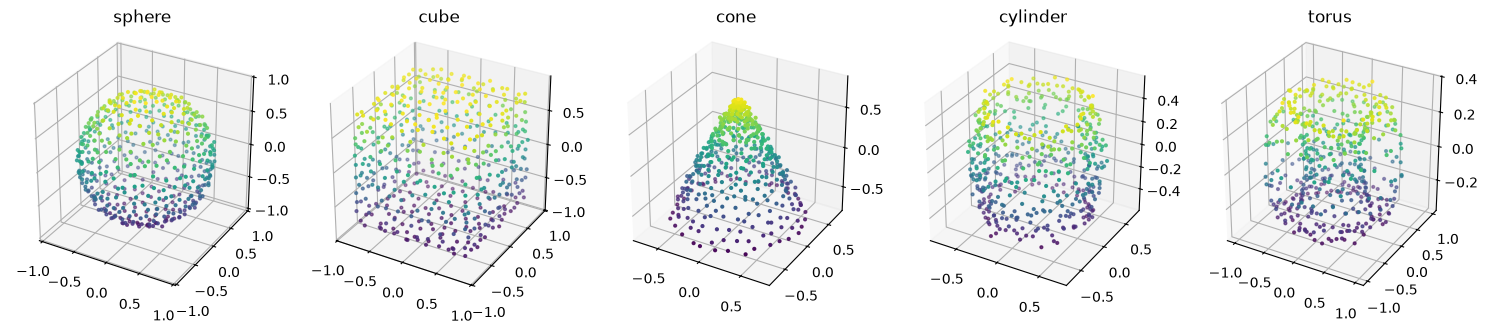

In [11]:
fig = plt.figure(figsize=(15, 3))
for i, shape in enumerate(SHAPE_CLASSES_3D):
    pts = generate_shape(pc_vae, shape)[0]
    ax = fig.add_subplot(1, len(SHAPE_CLASSES_3D), i + 1, projection="3d")
    plot_3d_points(pts, title=shape, ax=ax)
plt.tight_layout()
plt.show()


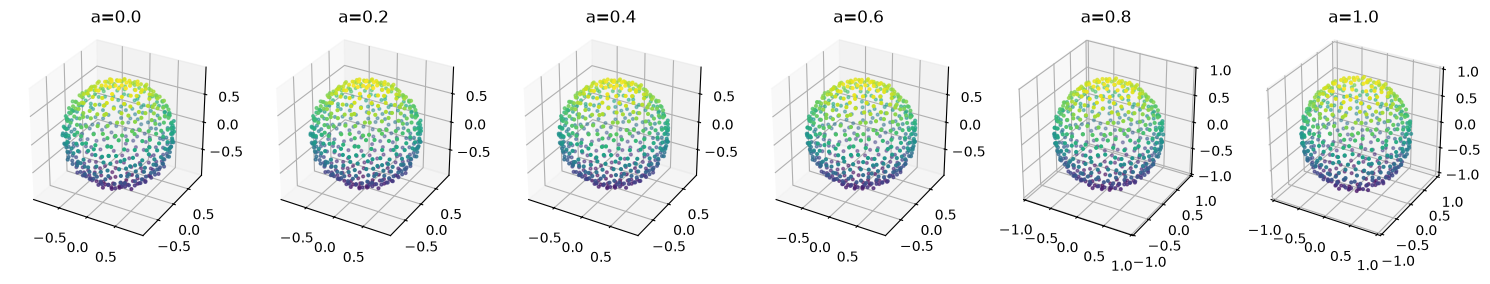

In [12]:
# Latent-space interpolation between two random shapes -- a smooth walk between
# latent codes should decode into a smooth morph, showing the latent space is meaningful.
@torch.no_grad()
def interpolate_shapes(model, class_a, class_b, steps=6, latent_dim=64):
    model.eval()
    za = torch.randn(1, latent_dim, device=DEVICE)
    zb = torch.randn(1, latent_dim, device=DEVICE)
    fig = plt.figure(figsize=(steps * 2.5, 2.5))
    for i, alpha in enumerate(np.linspace(0, 1, steps)):
        z = (1 - alpha) * za + alpha * zb
        y = torch.tensor([SHAPE_CLASSES_3D.index(class_a)], device=DEVICE)
        pts = model.decoder(z, y)[0]
        ax = fig.add_subplot(1, steps, i + 1, projection="3d")
        plot_3d_points(pts, title=f"a={alpha:.1f}", ax=ax)
    model.train()
    plt.tight_layout()
    plt.show()


interpolate_shapes(pc_vae, "sphere", "torus")


### 7.8 User Input → Output Demo


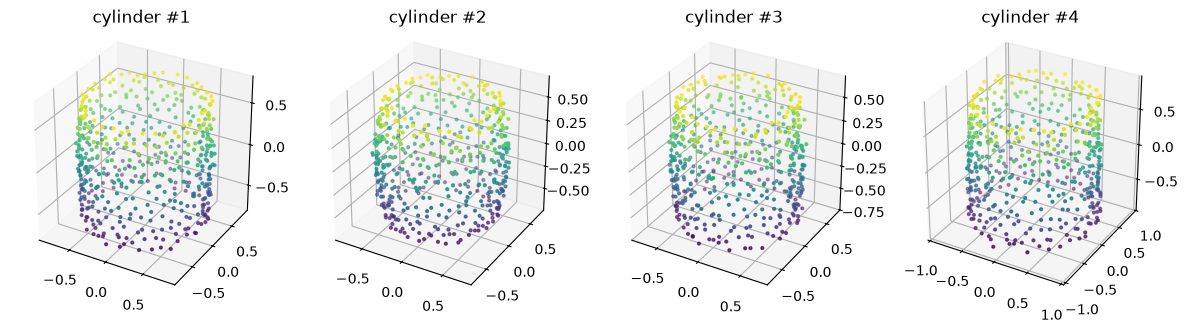

In [13]:
chosen_shape = "cylinder"  # <- pick any of SHAPE_CLASSES_3D
result = generate_shape(pc_vae, chosen_shape, n_samples=4)
fig = plt.figure(figsize=(12, 3))
for i in range(4):
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    plot_3d_points(result[i], title=f"{chosen_shape} #{i + 1}", ax=ax)
plt.tight_layout()
plt.show()


### 7.9 Key Insights, Limitations & Scaling Notes

- 🔥 **This model solved the problem of:** generating novel, class-conditioned 3D point clouds from a learned latent space, using an order-invariant encoder and a permutation-free reconstruction loss.
- 💡 **Insight:** the smooth interpolation result is the real evidence the model learned *shape*, not memorization -- a latent space that only memorized training examples would produce discontinuous jumps, not gradual morphs.
- ⚠️ **Limitation:** the fully-connected decoder outputs a fixed number of points with no explicit surface/mesh structure, and Chamfer distance alone doesn't guarantee uniform point density -- generated clouds can look "clumpy" compared to the training data.
- 🚀 **Scaling path:** move from synthetic primitives to a real ShapeNet subset, replace the MLP decoder with a diffusion or flow-based generator over points (better for multi-modal shape distributions within one class), or export to a mesh via Poisson surface reconstruction for renderable 3D assets.


---
## This notebook is part of a series

This model solved the problem of: **generating novel, class-conditioned 3D point clouds from a learned latent space**.

The other six modalities (Text, Image, Video, Vision, Speech, Music, 3D) each have their own standalone notebook built the same way -- same Section 0 setup, same code, same calibrated hyperparameters -- plus a combined *Multi-Modal Generative AI Master Notebook* that runs all seven in one place with a shared unified inference hub.
